# CampusDB: admissions and results analytics (PostgreSQL + pandas)

**Problem 01, Education.** Loads the CampusDB CSV files into PostgreSQL through the Python **DB-API**
(`psycopg2`), runs the analytical queries from `queries.sql`, and charts admissions and pass-rate trends.

**Data source.** All data is *synthetic*, generated by `python/gen_data.py` (random seed 2026): 4 departments,
6 programmes, 48 courses, 411 students, 2,888 enrolments, 216 exams and 2,888 results. Marks follow a hidden
student ability plus a course difficulty and noise, so the patterns are plausible but not real people.

**Before running:** `createdb campusdb_py`, then set `PGHOST`, `PGUSER`, `PGPASSWORD` if needed.

In [1]:
import os, csv, json
from pathlib import Path
import pandas as pd
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt

DB = os.getenv("CAMPUS_DB", "campusdb_py")
try:
    import psycopg2                                   # the normal DB-API driver for PostgreSQL
    def get_conn():
        return psycopg2.connect(dbname=DB, host=os.getenv("PGHOST", "localhost"),
                                user=os.getenv("PGUSER", "postgres"), password=os.getenv("PGPASSWORD", ""))
    DRIVER = "psycopg2"
except ImportError:                                   # sandbox without psycopg2: psql-backed DB-API wrapper
    sys.path.insert(0, "python")
    from psql_dbapi_shim import connect
    def get_conn():
        return connect(dbname=DB)
    DRIVER = "psql DB-API shim (psycopg2 not installed)"

conn = get_conn()
cur = conn.cursor()
cur.execute("SELECT version()")
print("driver  :", DRIVER)
print("database:", DB)
print("server  :", cur.fetchone()[0].split(",")[0])

driver  : psql DB-API shim (psycopg2 not installed)
database: campusdb_py
server  : PostgreSQL 16.15 (Ubuntu 16.15-0ubuntu0.24.04.1) on x86_64-pc-linux-gnu


## 1. Create the schema (`schema.sql`)

In [2]:
cur.execute(Path("sql/schema.sql").read_text())      # tables, constraints, function, 2 triggers, 2 views
conn.commit()
cur.execute("""SELECT table_name FROM information_schema.tables
               WHERE table_schema = 'public' ORDER BY table_type, table_name""")
print([r[0] for r in cur.fetchall()])

['course', 'department', 'enrolment', 'exam', 'programme', 'result', 'student', 'v_course_pass_rate', 'v_result_detail']


## 2. Load the CSV files with `executemany` (parent tables first)

In [3]:
LOAD_ORDER = ["department", "programme", "course", "student", "enrolment", "exam", "result"]
loaded = {}
for table in LOAD_ORDER:
    with open(f"data/{table}.csv", newline="") as f:
        rows = list(csv.reader(f))
    header, body = rows[0], rows[1:]
    sql = f"INSERT INTO {table} ({', '.join(header)}) VALUES ({', '.join(['%s'] * len(header))})"
    cur.executemany(sql, body)                         # result rows fire the CGPA trigger
    loaded[table] = len(body)
conn.commit()
for t in LOAD_ORDER:                                   # keep SERIAL sequences in step with the loaded ids
    pk = {"department": "dept_id", "programme": "programme_id"}.get(t, t + "_id")
    cur.execute(f"SELECT setval(pg_get_serial_sequence('{t}', '{pk}'), (SELECT MAX({pk}) FROM {t}))")
conn.commit()
print(loaded)
print("total rows loaded:", sum(loaded.values()))

{'department': 4, 'programme': 6, 'course': 48, 'student': 411, 'enrolment': 2888, 'exam': 216, 'result': 2888}
total rows loaded: 6461


## 3. Helper: run SQL, get a pandas DataFrame

In [4]:
def query(sql, params=None):
    cur.execute(sql, params)
    cols = [d[0] for d in cur.description]
    df = pd.DataFrame(cur.fetchall(), columns=cols)
    for c in df.columns:                               # psycopg2 returns Decimal/str, the shim returns str
        try:
            df[c] = pd.to_numeric(df[c])
        except (ValueError, TypeError):
            pass
    return df

counts = query("""
    SELECT 'department' AS tbl, COUNT(*) AS n FROM department UNION ALL
    SELECT 'programme', COUNT(*) FROM programme UNION ALL SELECT 'course', COUNT(*) FROM course UNION ALL
    SELECT 'student', COUNT(*) FROM student UNION ALL SELECT 'enrolment', COUNT(*) FROM enrolment UNION ALL
    SELECT 'exam', COUNT(*) FROM exam UNION ALL SELECT 'result', COUNT(*) FROM result""")
print(counts.to_string(index=False))
print("TOTAL ROWS:", int(counts.n.sum()))

       tbl    n
department    4
 programme    6
    course   48
   student  411
 enrolment 2888
      exam  216
    result 2888
TOTAL ROWS: 6461


## 4. Trigger from Python: CGPA recomputes when a mark changes

In [5]:
sid = 1
before = query("SELECT reg_no, cgpa FROM student WHERE student_id = %s", (sid,))
rid, old_marks = query("""SELECT r.result_id, r.marks_obtained FROM result r
                          JOIN enrolment e USING (enrolment_id)
                          WHERE e.student_id = %s ORDER BY r.result_id LIMIT 1""", (sid,)).iloc[0]
cur.execute("UPDATE result SET marks_obtained = %s WHERE result_id = %s", (99, int(rid)))
after = query("SELECT cgpa FROM student WHERE student_id = %s", (sid,))
cur.execute("UPDATE result SET marks_obtained = %s WHERE result_id = %s", (float(old_marks), int(rid)))   # restore
restored = query("SELECT cgpa FROM student WHERE student_id = %s", (sid,))
print(f"{before.reg_no[0]}: CGPA {before.cgpa[0]}  ->  {after.cgpa[0]} (one mark {old_marks} -> 99)  ->  {restored.cgpa[0]} (restored)")
try:
    cur.execute("UPDATE result SET marks_obtained = 120 WHERE result_id = %s", (int(rid),))
except Exception as e:
    print("validation trigger rejected marks 120:", str(e).splitlines()[0])

21BCS001: CGPA 8.0  ->  8.3 (one mark 79.34 -> 99)  ->  8.0 (restored)
validation trigger rejected marks 120: psql:<stdin>:1: ERROR:  Marks 120.00 exceed the exam maximum 100


## 5. Charts

Styling is shared by all charts: white surface, thin marks, quiet grid, direct value labels where they fit.
Colours follow a fixed categorical order, one hue per programme in every chart.

In [6]:
INK, MUTED, GRID = "#0b0b0b", "#52514e", "#e4e3df"
SERIES = {"BCS": "#2a78d6", "MDS": "#eb6834", "MBA": "#1baf7a", "MST": "#e87ba4", "BMA": "#6250d6", "BBT": "#eda100"}
plt.rcParams.update({"font.family": "DejaVu Sans", "font.size": 8.5, "text.color": INK, "axes.labelcolor": MUTED,
                     "xtick.color": MUTED, "ytick.color": MUTED, "axes.edgecolor": GRID, "axes.facecolor": "white",
                     "figure.facecolor": "white", "axes.spines.top": False, "axes.spines.right": False})
Path("outputs").mkdir(exist_ok=True)

def finish(fig, name):
    fig.savefig(f"outputs/{name}.png", dpi=220, facecolor="white")
    plt.show()

### Chart 1: admissions trend per programme

total admitted per year: {2021: 68, 2022: 72, 2023: 80, 2024: 91, 2025: 100}
2021 -> 2025 growth: 47%; MDS 9 -> 22; BMA 12 -> 9


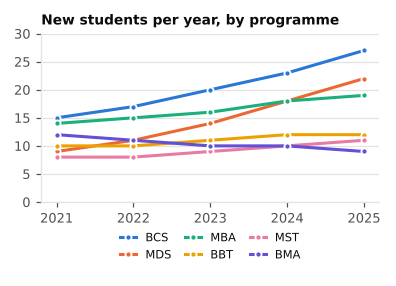

In [7]:
adm = query("""SELECT p.programme_code, s.admission_year AS year, COUNT(*) AS admitted
               FROM student s JOIN programme p ON p.programme_id = s.programme_id
               GROUP BY 1, 2 ORDER BY 1, 2""")
piv = adm.pivot(index="year", columns="programme_code", values="admitted")
order = piv.iloc[-1].sort_values(ascending=False).index          # legend order = latest value, high to low
fig, ax = plt.subplots(figsize=(3.6, 2.6))
for code_ in order:
    ax.plot(piv.index, piv[code_], color=SERIES[code_], lw=2, marker="o", ms=4, mec="white", mew=1.2, label=code_)
ax.set_xticks(piv.index); ax.set_ylim(0, 30)
ax.grid(axis="y", color=GRID, lw=0.8); ax.set_axisbelow(True)
ax.set_title("New students per year, by programme", loc="left", fontsize=9, fontweight="bold", color=INK)
ax.legend(ncol=3, frameon=False, fontsize=7.5, loc="upper center", bbox_to_anchor=(0.5, -0.12), handlelength=1.4, columnspacing=1.2)
fig.tight_layout()
finish(fig, "chart1_admissions_trend")
tot = piv.sum(axis=1)
print("total admitted per year:", tot.to_dict())
print(f"2021 -> 2025 growth: {tot[2025] / tot[2021] - 1:.0%}; MDS {piv.MDS[2021]} -> {piv.MDS[2025]}; BMA {piv.BMA[2021]} -> {piv.BMA[2025]}")

### Chart 2: pass percentage by course (lowest 8)

programme_code course_code         course_title  appeared  passed  pass_pct
           BCS      BCS320    Operating Systems        75      65      86.7
           MST      MST220      Sampling Theory        46      40      87.0
           MBA      MBA310  Business Statistics        63      55      87.3
           MDS      MDS220   Probability Theory        74      65      87.8
           BCS      BCS120 Discrete Mathematics       102      90      88.2
overall pass %: 93.7


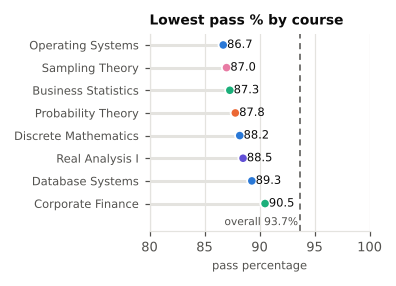

In [8]:
pr = query("SELECT programme_code, course_code, course_title, appeared, passed, pass_pct FROM v_course_pass_rate ORDER BY pass_pct, course_code")
overall = query("SELECT ROUND(100.0 * COUNT(*) FILTER (WHERE passed) / COUNT(*), 1) AS p FROM v_result_detail").p[0]
low = pr.head(8).iloc[::-1]
fig, ax = plt.subplots(figsize=(3.6, 2.6))
ax.hlines(range(len(low)), 80, low.pass_pct, color=GRID, lw=2)
ax.scatter(low.pass_pct, range(len(low)), s=38, color=[SERIES[c] for c in low.programme_code], zorder=3, edgecolor="white", linewidth=1.2)
for i, v in enumerate(low.pass_pct):
    ax.text(v + 0.35, i, f"{v:.1f}", va="center", fontsize=7.5, color=INK)
ax.set_yticks(range(len(low))); ax.set_yticklabels(low.course_title, fontsize=7.5)
ax.axvline(overall, color=MUTED, lw=1, ls=(0, (4, 3)))
ax.text(overall - 0.2, -0.95, f"overall {overall:.1f}%", fontsize=7, color=MUTED, ha="right")
ax.set_xlim(80, 100); ax.set_ylim(-1.2, len(low) - 0.5)
ax.grid(axis="x", color=GRID, lw=0.8); ax.set_axisbelow(True); ax.set_xlabel("pass percentage", fontsize=7.5)
ax.set_title("Lowest pass % by course", loc="left", fontsize=9, fontweight="bold", color=INK)
fig.tight_layout()
finish(fig, "chart2_pass_rate_by_course")
print(pr.head(5).to_string(index=False))
print("overall pass %:", overall)

### Chart 3: does the entrance score predict CGPA?

entrance_band  students  avg_cgpa
     below 60        94      4.63
        60-69       155      6.44
        70-79       123      7.57
          80+        39      8.52


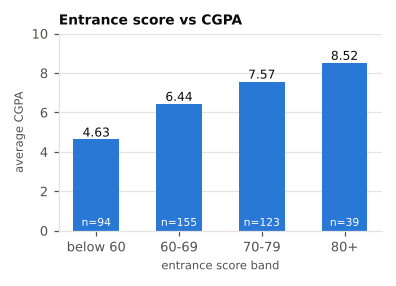

In [9]:
band = query("""SELECT CASE WHEN entrance_score >= 80 THEN '80+' WHEN entrance_score >= 70 THEN '70-79'
                            WHEN entrance_score >= 60 THEN '60-69' ELSE 'below 60' END AS entrance_band,
                       COUNT(*) AS students, ROUND(AVG(cgpa), 2) AS avg_cgpa, MIN(entrance_score) AS lo
                FROM student GROUP BY 1 ORDER BY lo""")
fig, ax = plt.subplots(figsize=(3.6, 2.6))
bars = ax.bar(band.entrance_band, band.avg_cgpa, color=SERIES["BCS"], width=0.55)
for b, v, n in zip(bars, band.avg_cgpa, band.students):
    ax.text(b.get_x() + b.get_width() / 2, v + 0.15, f"{v:.2f}", ha="center", fontsize=8, color=INK)
    ax.text(b.get_x() + b.get_width() / 2, 0.25, f"n={n}", ha="center", fontsize=7, color="white")
ax.set_ylim(0, 10); ax.grid(axis="y", color=GRID, lw=0.8); ax.set_axisbelow(True)
ax.set_xlabel("entrance score band", fontsize=7.5); ax.set_ylabel("average CGPA", fontsize=7.5)
ax.set_title("Entrance score vs CGPA", loc="left", fontsize=9, fontweight="bold", color=INK)
fig.tight_layout()
finish(fig, "chart3_entrance_vs_cgpa")
print(band[["entrance_band", "students", "avg_cgpa"]].to_string(index=False))

## 6. Toppers and students below the CGPA cut-off

In [10]:
toppers = query("""
    WITH ranked AS (SELECT p.programme_code, s.reg_no, s.full_name, s.cgpa,
                           RANK() OVER (PARTITION BY s.programme_id ORDER BY s.cgpa DESC) AS rnk
                    FROM student s JOIN programme p USING (programme_id))
    SELECT programme_code, reg_no, full_name, cgpa FROM ranked WHERE rnk = 1 ORDER BY programme_code""")
print("Topper per programme"); print(toppers.to_string(index=False))
risk = query("SELECT COUNT(*) AS below_5 FROM student WHERE cgpa < 5.0").below_5[0]
n_students = query("SELECT COUNT(*) AS n FROM student").n[0]
print(f"\nStudents below CGPA 5.0: {risk} of {n_students} ({risk / n_students:.1%})")
toppers.to_csv("outputs/toppers_per_programme.csv", index=False)

Topper per programme
programme_code   reg_no       full_name  cgpa
           BBT 24BBT004    Bhavna Menon  9.25
           BCS 22BCS007        Uday Rao  9.41
           BMA 23BMA010     Meera Reddy  9.17
           MBA 25MBA001   Nikhil George  9.00
           MDS 25MDS018     Tarun Singh  9.71
           MST 25MST004 Suresh Kulkarni  9.47

Students below CGPA 5.0: 58 of 411 (14.1%)


## 7. Save the headline numbers (used in the presentation)

In [11]:
metrics = {
    "total_rows": int(counts.n.sum()), "tables": int(len(counts)),
    "students": int(n_students), "below_5": int(risk), "overall_pass_pct": float(overall),
    "admitted_2021": int(tot[2021]), "admitted_2025": int(tot[2025]),
    "mds_2021": int(piv.MDS[2021]), "mds_2025": int(piv.MDS[2025]),
    "bma_2021": int(piv.BMA[2021]), "bma_2025": int(piv.BMA[2025]),
    "band_80plus": float(band.avg_cgpa[band.entrance_band == "80+"].iloc[0]),
    "band_below60": float(band.avg_cgpa[band.entrance_band == "below 60"].iloc[0]),
    "hardest": [list(r) for r in pr.head(3)[["course_title", "pass_pct"]].itertuples(index=False)],
}
Path("outputs/metrics.json").write_text(json.dumps(metrics, indent=2))
print(json.dumps(metrics, indent=2))
conn.close()

{
  "total_rows": 6461,
  "tables": 7,
  "students": 411,
  "below_5": 58,
  "overall_pass_pct": 93.7,
  "admitted_2021": 68,
  "admitted_2025": 100,
  "mds_2021": 9,
  "mds_2025": 22,
  "bma_2021": 12,
  "bma_2025": 9,
  "band_80plus": 8.52,
  "band_below60": 4.63,
  "hardest": [
    [
      "Operating Systems",
      86.7
    ],
    [
      "Sampling Theory",
      87.0
    ],
    [
      "Business Statistics",
      87.3
    ]
  ]
}
